<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# <center> Проект: Анализ резюме из HeadHunter
   

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [2]:
#ваш код здесь
hh_df = pd.read_csv('data/dst-3.0_16_1_hh_database.csv', sep=';')
course_df = pd.read_csv('data/ExchangeRates.csv')

2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [3]:
#ваш код здесь
print(hh_df.head())

                                   Пол, возраст           ЗП   
0    Мужчина ,  39 лет , родился 27 ноября 1979   29000 руб.  \
1     Мужчина ,  60 лет , родился 20 марта 1959   40000 руб.   
2  Женщина ,  36 лет , родилась 12 августа 1982   20000 руб.   
3      Мужчина ,  38 лет , родился 25 июня 1980  100000 руб.   
4     Женщина ,  26 лет , родилась 3 марта 1993  140000 руб.   

                           Ищет работу на должность:   
0                            Системный администратор  \
1                               Технический писатель   
2                                           Оператор   
3  Веб-разработчик (HTML / CSS / JS / PHP / базы ...   
4                  Региональный менеджер по продажам   

                        Город, переезд, командировки   
0  Советск (Калининградская область) , не готов к...  \
1  Королев , не готов к переезду , готов к редким...   
2  Тверь , не готова к переезду , не готова к ком...   
3  Саратов , не готов к переезду , готов к редким...  

3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

4. Обратите внимание на информацию о числе непустых значений.

In [4]:
#ваш код здесь
print(hh_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Пол, возраст                     44744 non-null  object
 1   ЗП                               44744 non-null  object
 2   Ищет работу на должность:        44744 non-null  object
 3   Город, переезд, командировки     44744 non-null  object
 4   Занятость                        44744 non-null  object
 5   График                           44744 non-null  object
 6   Опыт работы                      44576 non-null  object
 7   Последнее/нынешнее место работы  44743 non-null  object
 8   Последняя/нынешняя должность     44742 non-null  object
 9   Образование и ВУЗ                44744 non-null  object
 10  Обновление резюме                44744 non-null  object
 11  Авто                             44744 non-null  object
dtypes: object(12)
memory usage: 4.1+

5. Выведите основную статистическую информацию о столбцах.


In [5]:
#ваш код здесь
print(hh_df.describe())

                                         Пол, возраст          ЗП   
count                                           44744       44744  \
unique                                          16003         690   
top     Мужчина ,  32 года , родился 17 сентября 1986  50000 руб.   
freq                                               18        4064   

       Ищет работу на должность:   
count                      44744  \
unique                     14929   
top      Системный администратор   
freq                        3099   

                             Город, переезд, командировки         Занятость   
count                                               44744             44744  \
unique                                              10063                38   
top     Москва , не готов к переезду , не готов к кома...  полная занятость   
freq                                                 1261             30026   

             График                                        Опыт работы   
cou

# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [6]:
#ваш код здесь

# создаём функцию, которая из признака "Образование и ВУЗ" забирает только уровень образования соискателя
def get_education(arg):
    arg = ' '.join(arg.split(' ')[:3])
    if 'Высшее' in arg:
        return 'высшее'
    elif 'Неоконченное высшее' in arg:
        return 'неоконченное высшее'
    elif 'Среднее специальное' in arg:
        return 'среднее специальное'
    elif 'Среднее образование' in arg:
        return 'среднее'

# создаём новый признак "Образование" применяя к признаку "Образование и ВУЗ" нашу функцию
hh_df['Образование'] = hh_df['Образование и ВУЗ'].apply(get_education)\
# удаляем уже не нужный нам признак
hh_df = hh_df.drop('Образование и ВУЗ', axis=1)

# Вывод ответа на задание
print(hh_df['Образование'].value_counts()['среднее'])
# 559

559


2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '. 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [7]:
#ваш код здесь

# функция переопределения пола на "М" и "Ж"
def gender_func(arg):
    arg = arg.split(' ')
    if arg[0] == 'Мужчина':
        return 'М'
    else:
        return 'Ж'
    
# функция определения возраста
def age_func(arg):
    arg_splitted = arg.split(' ')
    year_words=['год', 'года', 'лет']
    for index, item in enumerate (arg_splitted):
        if item in year_words:
            return int(arg_splitted[index-1])

# создаём новые признаки "Пол" и "Возраст" используя наши функции
hh_df['Пол'] = hh_df['Пол, возраст'].apply(gender_func)
hh_df['Возраст'] = hh_df['Пол, возраст'].apply(age_func)
# удаляем старые признаки
hh_df = hh_df.drop('Пол, возраст', axis=1)

# Вывод ответа на задание
mask = hh_df['Пол'] == 'Ж'
print(round((hh_df[mask]['Пол'].count() / hh_df['Пол'].count()) * 100, 2))
print(round(hh_df['Возраст'].mean(), 2))
# 19.07
# 32.2

19.07
32.2


3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [8]:
#ваш код здесь

# создаём функцию, которая переводит данные об опыте работы в месяцы
def months_work(arg):
    if arg is np.nan or arg == 'Не указано':
        return None
    year_words=['год', 'года', 'лет']
    month_words=['месяц', 'месяца', 'месяцев']
    arg_splitted = arg.split(' ')[:7]
    years = 0
    months = 0
    for index, item in enumerate (arg_splitted):
        if item in year_words:
            years = int(arg_splitted[index-1])
        if item in month_words:
            months = int(arg_splitted[index-1])
    return int(years*12 + months)

# создаём новый признак "Опыт работы (месяц)" применяя нашу функцию
hh_df['Опыт работы (месяц)'] = hh_df['Опыт работы'].apply(months_work)
# удаляем старый признак
hh_df = hh_df.drop('Опыт работы', axis=1)

# Вывод ответа на задание
print(round(hh_df['Опыт работы (месяц)'].median()))
# 100

100


4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [9]:
#ваш код здесь

# функция определения города, если город не входит в список городов миллионников, он помечается как "Другие"
def town_func(arg):
    arg = arg.split(' ')
    million_cities = ['Москва', 'Санкт-Петербург', 'Новосибирск', 'Екатеринбург', 'Нижний Новгород', 'Казань', 'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж', 'Волгоград' ]
    for index, item in enumerate (arg):
        if item in million_cities:
            return arg[index]
        else:
            return 'Другие'

# функция определения готовности соискателя к переезду
def business_trips_func(arg):
    true_value = ['готов к переезду', 'готова к переезду', 'хочу переехать']
    false_value = ['не готов к переезду', 'не готова к переезду']
    arg = arg.split(' , ')
    for true in true_value:
        if true in arg:
            return True
    for false in false_value:
        if false in arg:
            return False
    return False
    
# функция определения готовности соискателя к командировкам
def removal_func(arg):
    if ('не готов к переезду' in arg) or ('не готова к переезду' in arg):
        return False
    elif 'хочу' in arg:
        return True
    else:
        return True

# создаём новые признаки: Город, Готовность к переезду и Готовность к командировкам
hh_df['Город'] = hh_df['Город, переезд, командировки'].apply(town_func)
hh_df['Готовность к переезду'] = hh_df['Город, переезд, командировки'].apply(removal_func)
hh_df['Готовность к командировкам'] = hh_df['Город, переезд, командировки'].apply(business_trips_func)
# удаляем старые признаки
hh_df = hh_df.drop('Город, переезд, командировки', axis=1)

# Вывод ответа на задание

town_mask = hh_df['Город'] == 'Санкт-Петербург'
print(round(hh_df[town_mask]['Город'].count() / hh_df['Город'].count() * 100))
rev_mask = hh_df['Готовность к переезду'] == True 
bus_mask = hh_df['Готовность к командировкам'] == True
print(round(hh_df[rev_mask & bus_mask].shape[0] / hh_df.shape[0] * 100))

# Первый ответ верный, но второй ответ у меня не правильный, 
# я два часа пытался разобраться в чём проблема, но так и не смог, 
# даже смотря на исходный код в этом задание, вроде всё сделано также, 
# но ответ выводит другой, если вам не сложно, можете посмотреть мой код, если нет, 
# то я пойму, так как это достаточно долго и сложно
# 11
# 22

11
22


5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [10]:
#ваш код здесь

# создаём два списка, в первом тип занятости, во втором тип графика работы
lst_bus = ['полная занятость', 'частичная занятость', 'проектная работа', 'волонтерство', 'стажировка']
lst_work = ['полный день', 'сменный график', 'гибкий график', 'удалённая работа', 'вахтовый метод']
# создаём функцию, которая создаёт признаки мигалки, для каждого типа занятости и графика, со значениями True и False
def columns_func(lst_bus, lst_work, hh_df):
    for col_b in lst_bus:
        hh_df[col_b] = hh_df['Занятость'].apply(lambda x: col_b in x)
    for col_w in lst_work:
        hh_df[col_w] = hh_df['График'].apply(lambda x: col_w in x)
    
# используем нашу функцию
columns_func(lst_bus, lst_work, hh_df)  
# удаляем два старых признака
hh_df = hh_df.drop('Занятость', axis=1)
hh_df = hh_df.drop('График', axis=1)
# Вывод ответа на задание
print(hh_df[hh_df['проектная работа'] & hh_df['волонтерство']].shape[0])
print(hh_df[hh_df['гибкий график'] & hh_df['вахтовый метод']].shape[0])
# 436
# 2311
# Нам сказано, что нужно удалить все признаки мигалки, после ответов на задания, поэтому удаляем их
hh_df = hh_df.drop(['полная занятость', 'частичная занятость', 
'проектная работа', 'волонтерство', 'стажировка', 'полный день', 
'сменный график', 'гибкий график', 'удалённая работа', 'вахтовый метод'], axis=1)

436
2311


6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования: 
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [11]:
#ваш код здесь

# переводим данные в нужный временной формат
hh_df['Обновление резюме'] = pd.to_datetime(hh_df['Обновление резюме'], dayfirst=True)
hh_df['Обновление резюме'] = hh_df['Обновление резюме'].dt.date
course_df['date'] = pd.to_datetime(course_df['date'], dayfirst=True)
course_df['date'] = course_df['date'].dt.date
# разделяем признак по пробелу
hh_df['ЗП'] = hh_df['ЗП'].apply(lambda x: x.split(' '))
# создаём словарь, где ключи которого — варианты написания валют в данных, а значения — коды ISO
dc = {'грн.': 'UAH', 'USD': 'USD', 'EUR': 'EUR', 'бел.руб.': '	BYN', 'KGS': 'KGS', 'сум': 'UZS', 'AZN': 'AZN', 'KZT': 'KZT'}
# в цикле проходимся по значениям признака "ЗП" и если наименование валюты в рублях - оставляем всё как есть, иначе переводим какую-либо другую валюту в коды ISO
a = 0
for i in hh_df['ЗП']:
    if i[1] in dc:
        if i[1] == 'руб.':
            hh_df['ЗП'][a][1] = 'RUB'
        else:
            i[1] = dc[i[1]]
            hh_df['ЗП'][a][1] = i[1]

# создаём два новых признака "Сумма" и "Валюта", с помощью ламбда функции, просто отделяем первый элемент - сумма, второй - Валюта
hh_df['Сумма'] = hh_df['ЗП'].apply(lambda x: x[0])
hh_df['Валюта'] = hh_df['ЗП'].apply(lambda x: x[1])
# удаляем старый признак
hh_df = hh_df.drop('ЗП', axis=1)
# соединяем две таблицы "hh_df" и "course_df" по двум ключевым столбцам - дата и валюта
hh_df = hh_df.merge(course_df, how='left', left_on=['Обновление резюме', 'Валюта'], right_on=['date', 'currency'])

# признаки для рубля заполняем еденицами
hh_df = hh_df.fillna({'close': 1})
hh_df = hh_df.fillna({'proportion': 1})

# переводим этот признак в флот, чтобы произвести умножение
hh_df['Сумма'] = hh_df['Сумма'].astype(float)

# умножаем сумму желаемой зарабатной платы на курс и делим на пропорцию, тем самым получая новый признак - "ЗП(руб)"
hh_df['ЗП(руб)'] = hh_df['Сумма'] * hh_df['close'] / hh_df['proportion']
# удаляем старые и ненужные признаки
hh_df = hh_df.drop(['Сумма', 'close', 'proportion', 'currency', 'date', 'Валюта', 'per', 'time', 'vol'], axis=1)
# вывод ответа на задание
print(hh_df['ЗП(руб)'].median()/1000)
# 58.0
# можете пожалуйста подсказать, что я именно сделал не так, 
# так как мой ответ отличается на еденицу от исходного

<temp>:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  course_df['date'] = pd.to_datetime(course_df['date'], dayfirst=True)


58.0


# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

In [14]:
# ваш код здесь

hist = px.histogram(
    data_frame=hh_df, 
    x='Возраст', title='Распределение возраста соискателей', 
    marginal='box'
)

hist.update_layout(yaxis_title='Количество')
hist.show()

ваши выводы по графику здесь

чему равна мода распределения? - мода равна 30 годам, туда входят 2834 соискателя

каковы предельные значения признака? - предельное значение равно 100 годам

в каком примерном интервале находится возраст большинства соискателей? - от 27 до 32

есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу? - все анамалии можно увидеть на коробчатой диаграмме, однако если думать логически, возраст от 50 до 60 лет, ещё может считаться нормой, судя по количеству входящих в эту возрастную группу 

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

In [11]:
# ваш код здесь

hist =px.histogram(
    data_frame=hh_df, x='Опыт работы (месяц)', 
    title='Распределение опыта работы соискателей', 
    marginal='box'
)

hist.show()

ваши выводы здесь

чему равна мода распределения? - мода равна 80 - 84 месяцам работы, (около 7 лет), туда входят 1414 соискателя

каковы предельные значения признака? - предельное значение равно 1188 месяцам работы, (около 99 лет)

в каком примерном интервале находится опыт работы большинства соискателей? - от 80 до 84 месяцев (около 7 лет), туда входят 1414 соискателя

есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу? - я считаю, что аномалиями в этом признаке можно считать все значения выше 450 месяцев работы (около 37,5 лет)

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для  заработной платы? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


In [12]:
# ваш код здесь

hist = px.histogram(
    data_frame=hh_df, x='ЗП(руб)', 
    marginal='box', 
    nbins=25, width=600, 
    histnorm='percent', 
    title='Распределение желаемой заработной платы соискателей'
)

hist.show()

mask = hh_df['ЗП(руб)'] < 1000000
hist_mask = px.histogram(
    data_frame=hh_df[mask], 
    x='ЗП(руб)', 
    marginal='box', 
    nbins=25, 
    width=600, 
    histnorm='percent', 
    title='Распределение желаемой заработной платы меньше миллиона'
)

hist_mask.show()

ваши выводы здесь

каковы предельные значения признака? - около 24 миллионов рублей

в каком примерном интервале находится заработная плата большинства соискателей? - (25 - 75 тысяч рублей)

есть ли аномалии для признака заработной платы? - я считаю аномалиями в этом признаке всё, что выше миллиона рублей

4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

In [13]:
# ваш код здесь

mask = hh_df['ЗП(руб)']<1e6
group = hh_df[mask].groupby(by='Образование')['ЗП(руб)'].median()
scatter = px.scatter(
    data_frame=group, 
    title='Зависимость медианной желаемой заработной платы от уровня образования'
)

scatter.show()

ваши выводы здесь

для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? - наибольшая желаемая заработная плата наблюдается у высшего образования(60 тысяч рублей), а наименьшие значения наблюдаются у среднего и специального среднего(40 тысяч рублей)

как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы? - да, так как на этом графике мы наблюдаем явную зависимость этих двух прихнаков

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

In [14]:
# ваш код здесь

mask = hh_df['ЗП(руб)'] < 1e6
box = px.box(
    data_frame=hh_df[mask], 
    color='Город', 
    x='Город', 
    y='ЗП(руб)', 
    title='Распределение медианной желаемой заработной платы в зависимости от города'
)

box.show()

ваши выводы здесь

как соотносятся медианные уровни желаемой заработной платы и их размах в городах? - чем больше сам город и его население, тем больше медианна желаемой заработной платы

как вы считаете, важен ли признак города при прогнозировании заработной платы? - да

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

In [97]:
# ваш код здесь

mask = hh_df['ЗП(руб)']<1e6
group = hh_df[mask].groupby(['Готовность к командировкам', 'Готовность к переезду'], as_index=False)['ЗП(руб)'].median()
bar = px.bar(
    data_frame=group,
    y='ЗП(руб)',
    x='Готовность к переезду',
    barmode="group",
    color='Готовность к командировкам',
    orientation='v',
    title='Медианная з/п по готовности к командировкам/переезду'
)

bar.show()


ваши выводы здесь

**к сожалению спустя много попыток я так и не смог понять, почему у меня отсутствует значение True для признака "Готовность к командировкам", могу расчитывать только на вашу обратную связь**

из графика видно, что у людей готовых на переезд желаемая заработная плата выше и также у людей, которые готовы к командировкам желаемая заработная плата тоже выше

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

In [100]:
# ваш код здесь

pivot = hh_df.pivot_table(values='ЗП(руб)', columns='Возраст', index='Образование', aggfunc='median')
imshow = px.imshow(pivot, color_continuous_scale='greens')
imshow.show()

ваши выводы здесь

из тепловой карты видно, что наибольшие желаемые заработные платы у людей с высшем образованием, а наименьшие у людей со среднем специальным, схожие желаемые заработные платы людей с разным образованием наблюдаются с 35 до 50 лет

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

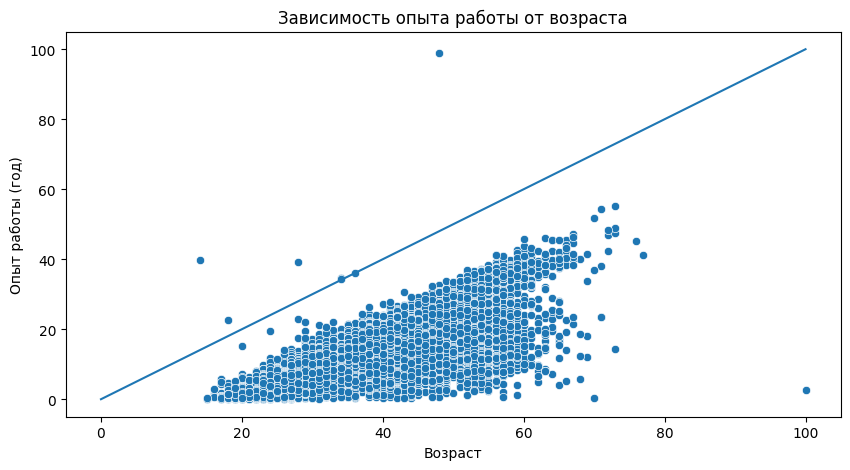

In [17]:
# ваш код здесь

copy_data = hh_df.copy()
copy_data['Опыт работы (год)'] = copy_data['Опыт работы (месяц)'].apply(lambda x: x/12)
fig = plt.figure(figsize=(10, 5))
sns.lineplot(x=[0, 100], y=[0, 100])
ax = sns.scatterplot(
    data=copy_data, 
    x='Возраст',
    y='Опыт работы (год)',
)
ax.set_title('Зависимость опыта работы от возраста');

ваши выводы здесь

на этой диаграмме видно шесть точек выше линии, то-есть шесть аномалий 

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


In [31]:
# ваш код здесь

scatter = px.scatter(data_frame=hh_df, 
    x='Возраст', 
    y='Опыт работы (месяц)', 
    title='Зависимость опыта работы от возраста'
)

scatter.show()

mask = hh_df['ЗП(руб)']<1e6
group = hh_df[mask].groupby(by='Пол')['ЗП(руб)'].median()
bar = px.bar(data_frame=group, color=group.index, title='Зависимость заработной платы от пола')
bar.show()

ваши выводы здесь

на первом графике мы можем вывести формулу, что чем старше соискатель, тем больше у него опыта работы, к предельным значениям можно отнести возраст(100 лет) и опыт работы(1188 месяцев, это 99 лет)

на втором графике мы видим, что женщины зарабатывают по медианне меньше мужчин на 13 тысяч рублей, женщины зарабатывают(47 тысяч рублей), мужчины(60 тысяч рублей)

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [89]:
# ваш код здесь

hh_df = hh_df.drop_duplicates()

2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [90]:
# ваш код здесь

empty = hh_df.isnull().sum()
print(empty)

Ищет работу на должность:            0
Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Обновление резюме                    0
Авто                                 0
Образование                          0
Пол                                  0
Возраст                              0
Опыт работы (месяц)                168
Город                                0
Готовность к переезду                0
Готовность к командировкам           0
ЗП(руб)                              0
dtype: int64


3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [91]:
# ваш код здесь

hh_df = hh_df.dropna(subset=['Последнее/нынешнее место работы', 'Последняя/нынешняя должность'])
hh_df = hh_df.fillna(hh_df['Опыт работы (месяц)'].median())

4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [92]:
# ваш код здесь

outliers = hh_df[hh_df['ЗП(руб)']<1000].index
outliers_1 = hh_df[hh_df['ЗП(руб)']>1e6].index
hh_df = hh_df.drop(outliers, axis=0)
hh_df = hh_df.drop(outliers_1, axis=0)

5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [93]:
# ваш код здесь

outliers = hh_df[hh_df['Опыт работы (месяц)'].apply(lambda x: x/12) >= hh_df['Возраст']].index
hh_df = hh_df.drop(outliers, axis=0)

6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

3


,Ищет работу на должность:,Последнее/нынешнее место работы,Последняя/нынешняя должность,Обновление резюме,Авто,Образование,Пол,Возраст,Опыт работы (месяц),Город,Готовность к переезду,Готовность к командировкам,ЗП(руб)
0,Системный администратор,"МАОУ ""СОШ № 1 г.Немана""",Системный администратор,2019-04-16,Имеется собственный автомобиль,неоконченное высшее,М,39,202.0,Другие,False,False,29000.0
1,Технический писатель,Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель",2019-04-12,Не указано,высшее,М,60,233.0,Другие,False,False,40000.0
2,Оператор,ПАО Сбербанк,Кассир-операционист,2019-04-16,Не указано,среднее специальное,Ж,36,123.0,Другие,False,False,20000.0
3,Веб-разработчик (HTML / CSS / JS / PHP / базы ...,OpenSoft,Инженер-программист,2019-04-08,Не указано,высшее,М,38,225.0,Другие,False,False,100000.0
4,Региональный менеджер по продажам,Мармелад,Менеджер по продажам,2019-04-22,Не указано,высшее,Ж,26,67.0,Москва,False,False,140000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
44739,"Финансист, аналитик, экономист, бухгалтер, мен...","ООО ""IAS"" (независимый участник объединения Ru...",Руководитель субгруппы,2019-04-22,Не указано,высшее,М,30,91.0,Другие,True,False,50000.0
44740,"Системный администратор, IT-специалист",ИП Пестрецов,Предприниматель,2019-04-22,Не указано,высшее,М,27,84.0,Другие,True,True,39000.0
44741,"Аналитик данных, Математик","ОАО «ЧМК», Исследовательско-Технологический Це...",Начальник группы аналитики,2019-04-09,Не указано,высшее,Ж,48,257.0,Челябинск,True,True,40000.0
44742,Контент-менеджер,IQ-Maxima,Менеджер проектов,2019-04-26,Имеется собственный автомобиль,высшее,М,24,46.0,Другие,False,False,20000.0


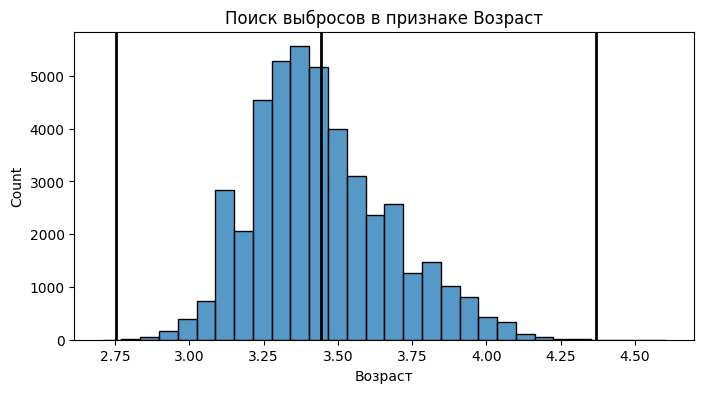

In [95]:
# ваш код здесь

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
log_age = np.log(hh_df['Возраст'])
hist = sns.histplot(log_age, ax=ax, bins=30)
hist.axvline(log_age.mean(), color='k', lw=2)
hist.axvline(log_age.mean()+ 4 * log_age.std(), color='k', lw=2)
hist.axvline(log_age.mean()- 3 * log_age.std(), color='k', lw=2)
hist.set_title('Поиск выбросов в признаке Возраст');

def emissions_z_lines(data, feature, left=3, right=3, log_scale=False):
    if log_scale:
        x = np.log(data[feature])
    else:
        x = data[feature]
    mu = x.mean()
    sigma = x.std()
    lower_bound = mu - (sigma * left)
    upper_bound = mu + (sigma * right)
    outliers = data[(x < lower_bound) | (x > upper_bound)]
    cleaned = data[(x >= lower_bound) & (x <= upper_bound)]
    return outliers, cleaned

outliers, cleaned = emissions_z_lines(hh_df, 'Возраст', log_scale=True, right=4, left=3)
print(outliers.shape[0])
hh_df.drop(outliers.index, axis=0)

ваш коммментарий здесь

в какую сторону асимметрично логарифмическое распределение? - в левую

с каким возрастом соискатели попадают под категорию выбросов? - в категорию выбросов попадают все с возрастом ниже 27.5 лет и выше 43 лет